In [5]:
import pandas as pd

url = "https://bulks-faostat.fao.org/production/Production_Crops_Livestock_E_All_Data_(Normalized).zip"

!wget -q -O faostat_crops.zip "https://bulks-faostat.fao.org/production/Production_Crops_Livestock_E_All_Data_(Normalized).zip"

print("Crop dataset downloaded successfully!")

Crop dataset downloaded successfully!


In [6]:
crop_data = pd.read_csv(
    "/content/faostat_crops.zip",
    usecols=["Area", "Item", "Element", "Year", "Unit", "Value"],
    low_memory=False
)

print("Dataset loaded successfully!")

print("Dataset shape:", crop_data.shape)

crop_data.head(10)

Dataset loaded successfully!
Dataset shape: (4209110, 6)


,Area,Item,Element,Year,Unit,Value
0,Afghanistan,"Almonds, in shell",Area harvested,1961,ha,0.0
1,Afghanistan,"Almonds, in shell",Area harvested,1962,ha,0.0
2,Afghanistan,"Almonds, in shell",Area harvested,1963,ha,0.0
3,Afghanistan,"Almonds, in shell",Area harvested,1964,ha,0.0
4,Afghanistan,"Almonds, in shell",Area harvested,1965,ha,0.0
5,Afghanistan,"Almonds, in shell",Area harvested,1966,ha,0.0
6,Afghanistan,"Almonds, in shell",Area harvested,1967,ha,0.0
7,Afghanistan,"Almonds, in shell",Area harvested,1968,ha,0.0
8,Afghanistan,"Almonds, in shell",Area harvested,1969,ha,0.0
9,Afghanistan,"Almonds, in shell",Area harvested,1970,ha,0.0


In [7]:
india_yields = crop_data[
    (crop_data["Area"] == "India") &
    (crop_data["Element"] == "Yield")
]

crop_names = [
    item for item in india_yields["Item"].unique()
    if any(word in item.lower()
           for word in ["wheat", "rice", "maize", "soybean"])
]

print("Available crop names:")
print(crop_names)


Available crop names:
['Maize (corn)', 'Rice', 'Wheat']


In [8]:
soya_names = [
    item for item in india_yields["Item"].unique()
    if "soy" in item.lower() or "soya" in item.lower()
]

print("Soybean-related names:")
print(soya_names)

Soybean-related names:
['Soya beans']


In [9]:
# Select our four crops
selected_crops = [
    "Wheat",
    "Rice",
    "Maize (corn)",
    "Soya beans"
]

# Filter the data
crop_clean = crop_data[
    (crop_data["Area"] == "India") &
    (crop_data["Item"].isin(selected_crops)) &
    (crop_data["Element"] == "Yield") &
    (crop_data["Year"].between(2000, 2024))
].copy()

# Keep only useful columns
crop_clean = crop_clean[
    ["Area", "Year", "Item", "Value", "Unit"]
]

# Rename columns
crop_clean.columns = [
    "Country", "Year", "Crop", "Yield", "Unit"
]

# Sort data
crop_clean = crop_clean.sort_values(
    ["Crop", "Year"]
).reset_index(drop=True)

# Display results
print("Clean dataset created!")
print("Dataset shape:", crop_clean.shape)
print("\nCrops included:")
print(crop_clean["Crop"].unique())

crop_clean.head(10)

Clean dataset created!
Dataset shape: (100, 5)

Crops included:
['Maize (corn)' 'Rice' 'Soya beans' 'Wheat']


,Country,Year,Crop,Yield,Unit
0,India,2000,Maize (corn),1799.2,kg/ha
1,India,2001,Maize (corn),1993.3,kg/ha
2,India,2002,Maize (corn),1688.5,kg/ha
3,India,2003,Maize (corn),2015.9,kg/ha
4,India,2004,Maize (corn),1868.2,kg/ha
5,India,2005,Maize (corn),1955.7,kg/ha
6,India,2006,Maize (corn),1811.1,kg/ha
7,India,2007,Maize (corn),2315.8,kg/ha
8,India,2008,Maize (corn),2276.5,kg/ha
9,India,2009,Maize (corn),2146.1,kg/ha


In [10]:
# 1. Check missing values
print("========== MISSING VALUES ==========")
print(crop_clean.isnull().sum())


# 2. Check duplicate records
print("\n========== DUPLICATE RECORDS ==========")
print("Total duplicates:", crop_clean.duplicated().sum())


# 3. Basic statistical analysis
print("\n========== BASIC STATISTICS ==========")
print(crop_clean.groupby("Crop")["Yield"].describe())


# 4. Dataset information
print("\n========== DATASET INFORMATION ==========")
crop_clean.info()

========== MISSING VALUES ==========
Country    0
Year       0
Crop       0
Yield      0
Unit       0
dtype: int64

========== DUPLICATE RECORDS ==========
Total duplicates: 0

========== BASIC STATISTICS ==========
              count      mean         std     min     25%     50%     75%  \
Crop                                                                        
Maize (corn)   25.0  2543.568  556.332730  1688.5  2015.9  2493.5  2998.1   
Rice           25.0  3556.424  479.687424  2690.1  3194.1  3601.8  3976.1   
Soya beans     25.0  1053.792  159.418006   738.5   950.8  1058.5  1176.6   
Wheat          25.0  3039.088  340.787593  2601.6  2749.6  2988.6  3368.2   

                 max  
Crop                  
Maize (corn)  3544.8  
Rice          4313.5  
Soya beans    1352.9  
Wheat         3559.0  

========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  

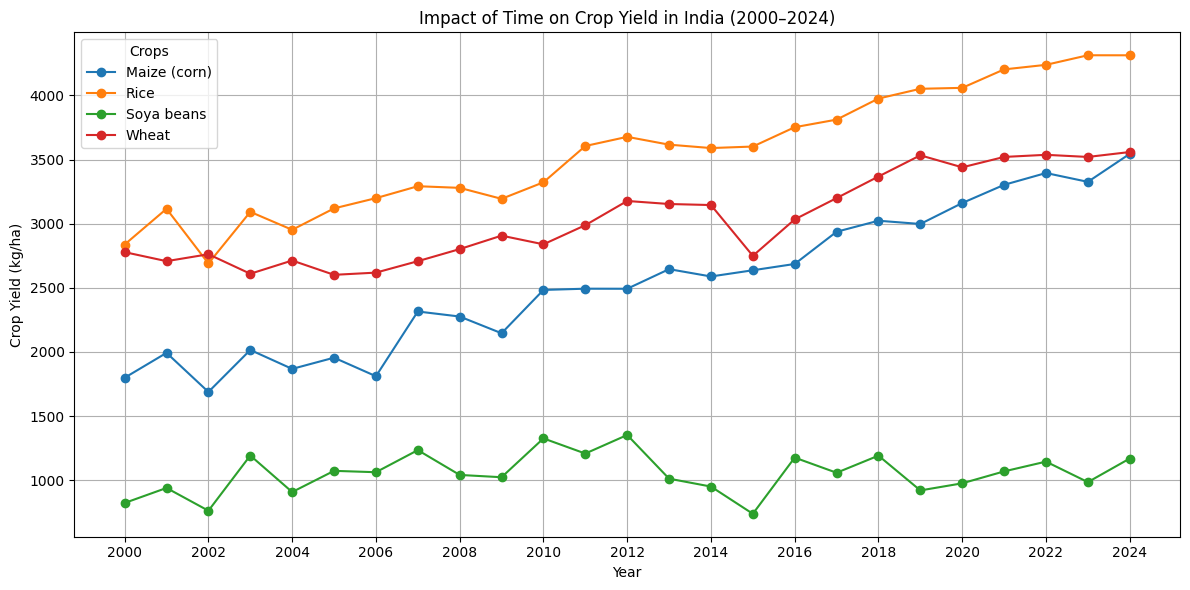

In [11]:
import matplotlib.pyplot as plt

# Create figure
plt.figure(figsize=(12, 6))

# Plot each crop
for crop in crop_clean["Crop"].unique():

    data = crop_clean[crop_clean["Crop"] == crop]

    plt.plot(
        data["Year"],
        data["Yield"],
        marker="o",
        label=crop
    )

# Add graph details
plt.title("Impact of Time on Crop Yield in India (2000–2024)")
plt.xlabel("Year")
plt.ylabel("Crop Yield (kg/ha)")

plt.legend(title="Crops")
plt.grid(True)

plt.xticks(range(2000, 2025, 2))
plt.tight_layout()

# Display graph
plt.show()

In [12]:
import requests
import json

# World Bank Climate Data API
url = (
    "https://datacatalogapi.worldbank.org/ddhxext/v3/cckp/"
    "cru-x0.5_timeseries_tas,pr_timeseries_annual_"
    "1901-2022_mean_historical_cru-ts4.07_all_mean/"
    "IND?_format=json"
)

print("Downloading India's climate data...")

response = requests.get(url, timeout=60)

print("Response status:", response.status_code)

response.raise_for_status()

climate_raw = response.json()

print("\nClimate data downloaded successfully!")
print("\nAvailable response information:")

if isinstance(climate_raw, dict):
    print("Keys:", list(climate_raw.keys()))

print("\nSample data:")
print(json.dumps(climate_raw, indent=2)[:4000])

Response status: 200

Climate data downloaded successfully!

Available response information:
Keys: ['metadata', 'data']

Sample data:
{
  "metadata": {
    "apiVersion": "v1",
    "status": "success",
    "messages": []
  },
  "data": {}
}


In [13]:
import requests
import json

url = (
    "https://cckpapi.worldbank.org/cckp/v1/"
    "cru-x0.5_timeseries_tas,pr_timeseries_annual_"
    "1901-2022_mean_historical_cru_ts4.07_all_all_mean/"
    "IND?_format=json"
)

print("Downloading climate data...")

response = requests.get(url, timeout=60)

print("Status:", response.status_code)
response.raise_for_status()

climate_raw = response.json()

print("\nResponse keys:", climate_raw.keys())
print("\nData preview:")
print(json.dumps(climate_raw.get("data"), indent=2)[:4000])


Status: 200

Response keys: dict_keys(['metadata', 'data'])

Data preview:
[]


In [14]:
import requests
import pandas as pd
import json

url = (
    "https://cckpapi.worldbank.org/cckp/v1/"
    "cru-x0.5_timeseries_tas,pr_timeseries_annual_"
    "1901-2022_mean_historical_cru-ts4.07_all_mean/"
    "IND?_format=json"
)

print("Downloading India's temperature and rainfall data...")

response = requests.get(url, timeout=120)
response.raise_for_status()

result = response.json()
data = result.get("data")

print("API status:", result.get("metadata", {}).get("status"))
print("Data type:", type(data).__name__)
print("Records received:", len(data) if isinstance(data, list) else len(data or {}))

print("\nData preview:")
print(json.dumps(data, indent=2)[:3000])

API status: success
Data type: list
Records received: 0

Data preview:
[]


In [15]:
import requests

url = "https://power.larc.nasa.gov/api/temporal/monthly/point"

# Correct parameters for the monthly point API
params = {
    "parameters": "T2M,PRECTOTCORR",
    "community": "AG",
    "longitude": 78.9629,
    "latitude": 20.5937,
    "start": "2000",      # Needs 4-digit year for monthly endpoint
    "end": "2024",        # Captures up to the latest crop yield year
    "format": "JSON"
}

print("Downloading climate data from NASA POWER...")
response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

weather_test = response.json()

print("NASA POWER connection successful!")
print("Available parameters:", list(weather_test["properties"]["parameter"].keys()))

NASA POWER connection successful!
Available parameters: ['PRECTOTCORR', 'T2M']


In [16]:
import requests
import pandas as pd

print("Downloading climate data from NASA POWER...")

url = "https://power.larc.nasa.gov/api/temporal/daily/point"

params = {
    "parameters": "T2M,PRECTOTCORR",
    "community": "AG",
    "longitude": 78.9629,
    "latitude": 20.5937,
    "start": "20000101",
    "end": "20241231",
    "format": "JSON"
}

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()

climate_json = response.json()

temperature = climate_json["properties"]["parameter"]["T2M"]
rainfall = climate_json["properties"]["parameter"]["PRECTOTCORR"]

climate_data = pd.DataFrame({
    "Date": list(temperature.keys()),
    "Temperature": list(temperature.values()),
    "Rainfall": list(rainfall.values())
})

climate_data["Date"] = pd.to_datetime(climate_data["Date"], format="%Y%m%d")
climate_data["Year"] = climate_data["Date"].dt.year

climate_yearly = climate_data.groupby("Year").agg(
    Avg_Temperature=("Temperature", "mean"),
    Total_Rainfall=("Rainfall", "sum")
).reset_index()

print("Climate data downloaded successfully!")
display(climate_yearly.head())
print("Total yearly records:", len(climate_yearly))

Climate data downloaded successfully!


,Year,Avg_Temperature,Total_Rainfall
0,2000,27.078934,766.66
1,2001,26.996329,974.62
2,2002,27.681616,909.58
3,2003,27.190904,1118.08
4,2004,27.241940,724.99


Total yearly records: 25


In [17]:
# Merge crop yield and climate data
final_data = pd.merge(
    crop_clean,
    climate_yearly,
    on="Year",
    how="inner"
)

# Display the combined dataset
display(final_data.head(10))

print("Total records:", len(final_data))
print("Missing values:")
print(final_data.isnull().sum())

,Country,Year,Crop,Yield,Unit,Avg_Temperature,Total_Rainfall
0,India,2000,Maize (corn),1799.2,kg/ha,27.078934,766.66
1,India,2001,Maize (corn),1993.3,kg/ha,26.996329,974.62
2,India,2002,Maize (corn),1688.5,kg/ha,27.681616,909.58
3,India,2003,Maize (corn),2015.9,kg/ha,27.190904,1118.08
4,India,2004,Maize (corn),1868.2,kg/ha,27.241940,724.99
5,India,2005,Maize (corn),1955.7,kg/ha,26.809041,1153.16
6,India,2006,Maize (corn),1811.1,kg/ha,26.878192,1328.48
7,India,2007,Maize (corn),2315.8,kg/ha,27.129342,943.35
8,India,2008,Maize (corn),2276.5,kg/ha,26.866585,889.28
9,India,2009,Maize (corn),2146.1,kg/ha,27.860219,931.69


Total records: 100
Missing values:
Country            0
Year               0
Crop               0
Yield              0
Unit               0
Avg_Temperature    0
Total_Rainfall     0
dtype: int64


In [18]:
# Calculate correlation for each crop

for crop in final_data["Crop"].unique():

    crop_data = final_data[final_data["Crop"] == crop]

    correlation = crop_data[
        ["Yield", "Avg_Temperature", "Total_Rainfall"]
    ].corr()

    print("\nCrop:", crop)
    print(correlation["Yield"])


Crop: Maize (corn)
Yield              1.000000
Avg_Temperature   -0.399074
Total_Rainfall     0.505228
Name: Yield, dtype: float64

Crop: Rice
Yield              1.000000
Avg_Temperature   -0.461501
Total_Rainfall     0.521835
Name: Yield, dtype: float64

Crop: Soya beans
Yield              1.000000
Avg_Temperature   -0.037544
Total_Rainfall     0.313530
Name: Yield, dtype: float64

Crop: Wheat
Yield              1.000000
Avg_Temperature   -0.352020
Total_Rainfall     0.381893
Name: Yield, dtype: float64


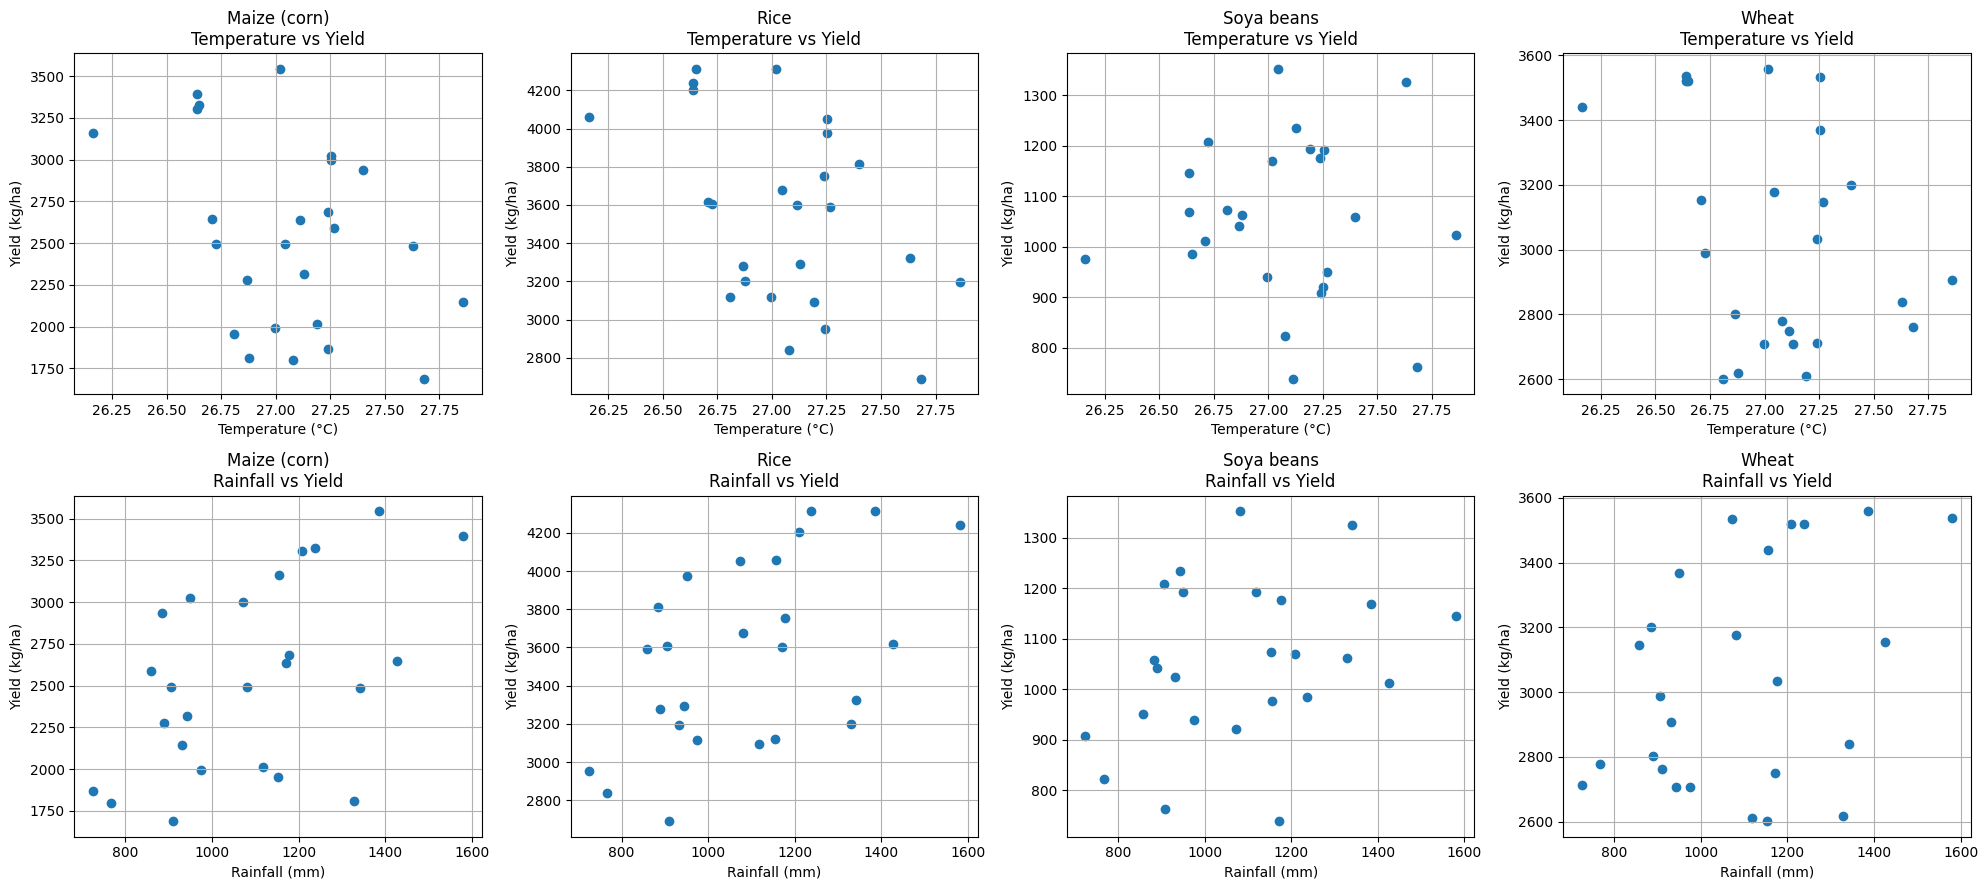

In [19]:
import matplotlib.pyplot as plt

crops = final_data["Crop"].unique()

fig, axes = plt.subplots(2, 4, figsize=(20, 9))

for i, crop in enumerate(crops):
    data = final_data[final_data["Crop"] == crop]

    # Temperature vs Yield
    axes[0, i].scatter(data["Avg_Temperature"], data["Yield"])
    axes[0, i].set_title(f"{crop}\nTemperature vs Yield")
    axes[0, i].set_xlabel("Temperature (°C)")
    axes[0, i].set_ylabel("Yield (kg/ha)")
    axes[0, i].grid(True)

    # Rainfall vs Yield
    axes[1, i].scatter(data["Total_Rainfall"], data["Yield"])
    axes[1, i].set_title(f"{crop}\nRainfall vs Yield")
    axes[1, i].set_xlabel("Rainfall (mm)")
    axes[1, i].set_ylabel("Yield (kg/ha)")
    axes[1, i].grid(True)

plt.tight_layout()
plt.show()

In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Prepare data
model_data = final_data.copy()

# Convert crop names into numerical columns
model_data = pd.get_dummies(model_data, columns=["Crop"], drop_first=True, dtype=int)

# Select input and output
X = model_data.drop(columns=["Country", "Year", "Yield", "Unit"])
y = model_data["Yield"]

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict yield
predictions = model.predict(X_test)

# Evaluate model
print("MODEL PERFORMANCE")
print("------------------")
print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 2))
print("R2 Score:", round(r2_score(y_test, predictions), 3))

# Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual Yield": y_test.values,
    "Predicted Yield": predictions.round(2)
})

display(comparison)

MODEL PERFORMANCE
------------------
MAE: 347.27
RMSE: 397.93
R2 Score: 0.797


,Actual Yield,Predicted Yield
0,2802.2,3057.81
1,1192.9,1052.61
2,976.2,1399.07
3,4059.4,3896.99
4,4052.1,3505.83
5,3590.0,3382.99
6,3395.4,2947.37
7,2601.6,3221.23
8,2483.8,2501.52
9,1799.2,2360.25


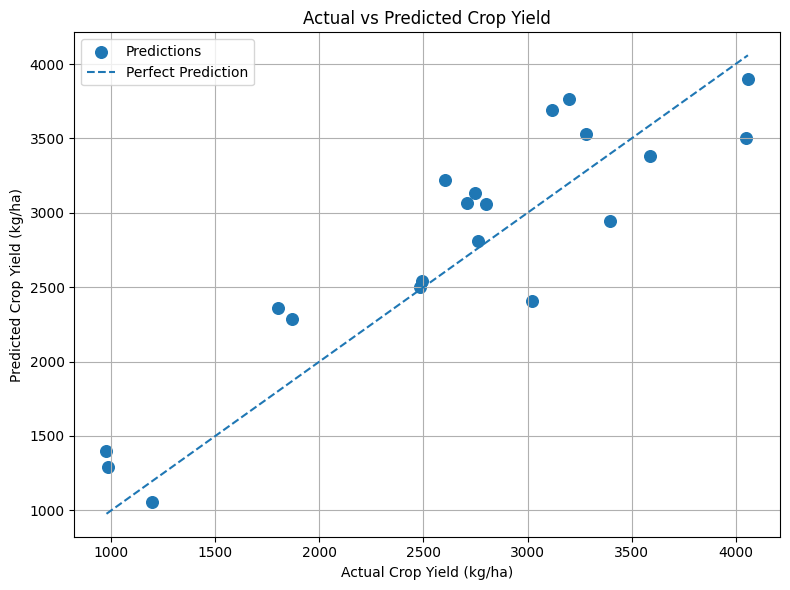

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, s=70, label="Predictions")

# Perfect prediction reference line
minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Crop Yield (kg/ha)")
plt.ylabel("Predicted Crop Yield (kg/ha)")
plt.title("Actual vs Predicted Crop Yield")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
# Time-based model testing
train_data = final_data[final_data["Year"] <= 2019].copy()
test_data = final_data[final_data["Year"] >= 2020].copy()

X_train = pd.get_dummies(
    train_data[["Avg_Temperature", "Total_Rainfall", "Crop"]],
    columns=["Crop"], dtype=int
)

X_test = pd.get_dummies(
    test_data[["Avg_Temperature", "Total_Rainfall", "Crop"]],
    columns=["Crop"], dtype=int
).reindex(columns=X_train.columns, fill_value=0)

y_train = train_data["Yield"]
y_test_future = test_data["Yield"]

future_model = LinearRegression()
future_model.fit(X_train, y_train)

future_predictions = future_model.predict(X_test)

print("FUTURE YEAR TEST (2020–2024)")
print("MAE:", round(mean_absolute_error(y_test_future, future_predictions), 2))
print("R2 Score:", round(r2_score(y_test_future, future_predictions), 3))

FUTURE YEAR TEST (2020–2024)
MAE: 570.19
R2 Score: 0.69


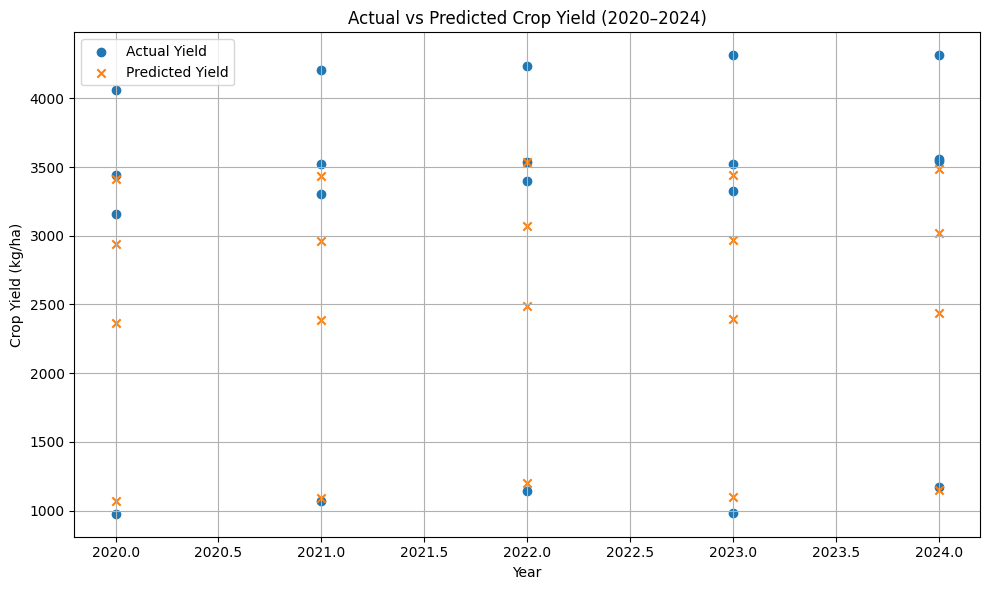

Final dataset saved successfully!


In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    test_data["Year"],
    y_test_future,
    label="Actual Yield",
    marker="o"
)

plt.scatter(
    test_data["Year"],
    future_predictions,
    label="Predicted Yield",
    marker="x"
)

plt.title("Actual vs Predicted Crop Yield (2020–2024)")
plt.xlabel("Year")
plt.ylabel("Crop Yield (kg/ha)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Save final dataset
final_data.to_csv("Climate_Crop_Yield_Analysis.csv", index=False)

print("Final dataset saved successfully!")

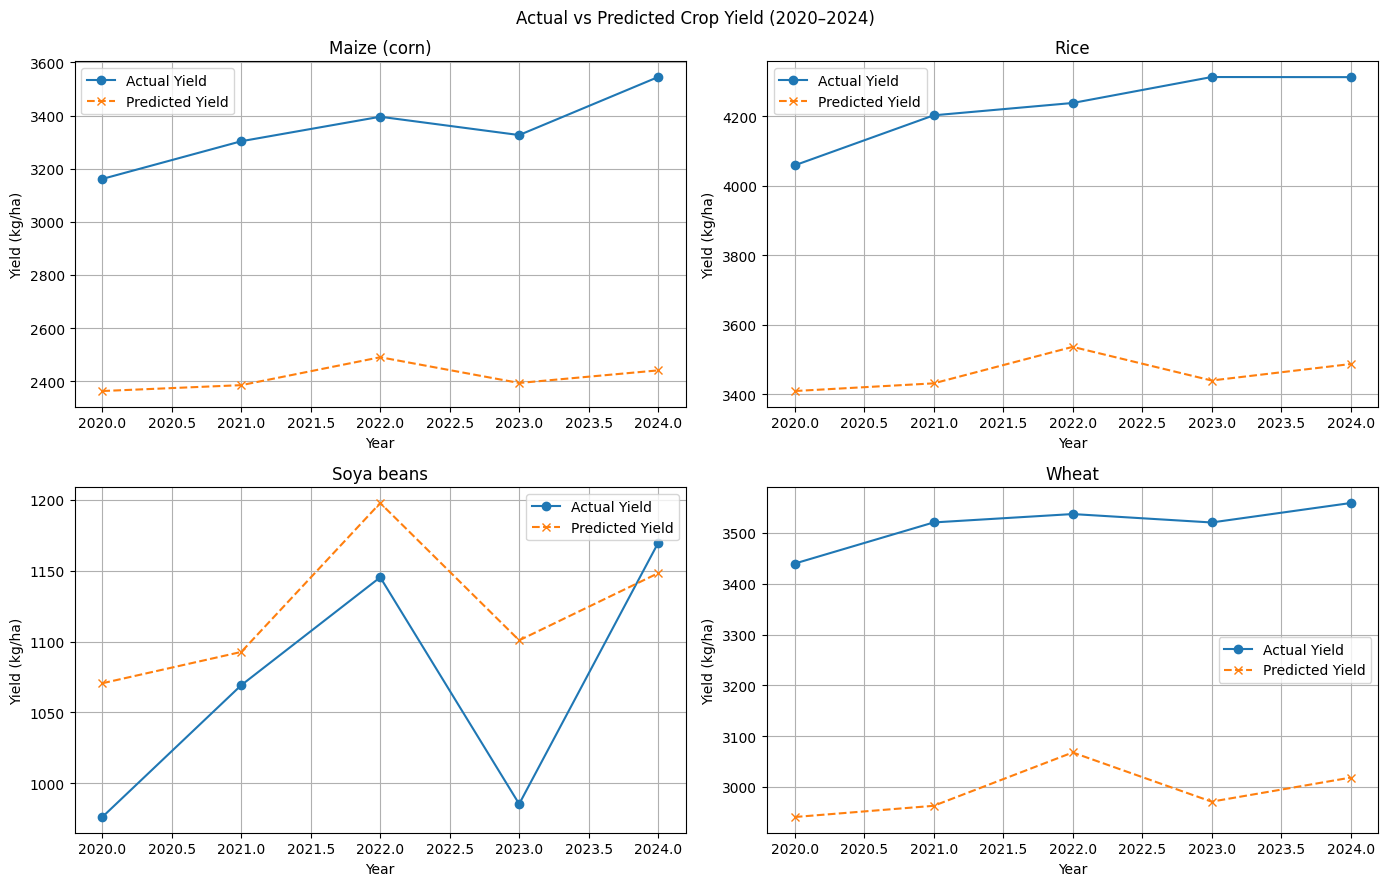

In [24]:
import matplotlib.pyplot as plt

# Prepare comparison data
test_results = test_data[["Year", "Crop"]].copy()
test_results["Actual Yield"] = y_test_future.values
test_results["Predicted Yield"] = future_predictions

# Create four separate graphs
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, crop in zip(axes.flatten(), test_results["Crop"].unique()):
    data = test_results[test_results["Crop"] == crop]

    ax.plot(data["Year"], data["Actual Yield"],
            marker="o", label="Actual Yield")

    ax.plot(data["Year"], data["Predicted Yield"],
            marker="x", linestyle="--", label="Predicted Yield")

    ax.set_title(crop)
    ax.set_xlabel("Year")
    ax.set_ylabel("Yield (kg/ha)")
    ax.legend()
    ax.grid(True)

plt.suptitle("Actual vs Predicted Crop Yield (2020–2024)")
plt.tight_layout()
plt.show()

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Separate training and testing data
train_data = final_data[final_data["Year"] <= 2019].copy()
test_data = final_data[final_data["Year"] >= 2020].copy()

# Select input features, including Year
X_train = pd.get_dummies(
    train_data[["Year", "Avg_Temperature", "Total_Rainfall", "Crop"]],
    columns=["Crop"],
    dtype=int
)

X_test = pd.get_dummies(
    test_data[["Year", "Avg_Temperature", "Total_Rainfall", "Crop"]],
    columns=["Crop"],
    dtype=int
).reindex(columns=X_train.columns, fill_value=0)

y_train = train_data["Yield"]
y_test = test_data["Yield"]

# Train improved model
improved_model = LinearRegression()
improved_model.fit(X_train, y_train)

# Make predictions
improved_predictions = improved_model.predict(X_test)

# Evaluate
print("IMPROVED MODEL PERFORMANCE")
print("---------------------------")
print("MAE:", round(mean_absolute_error(y_test, improved_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, improved_predictions)), 2))
print("R2 Score:", round(r2_score(y_test, improved_predictions), 3))

# Comparison
results = test_data[["Year", "Crop"]].copy()
results["Actual Yield"] = y_test.values
results["Predicted Yield"] = improved_predictions.round(2)

display(results)

IMPROVED MODEL PERFORMANCE
---------------------------
MAE: 320.24
RMSE: 382.01
R2 Score: 0.897


,Year,Crop,Actual Yield,Predicted Yield
20,2020,Maize (corn),3161.4,2878.83
21,2021,Maize (corn),3303.3,2878.77
22,2022,Maize (corn),3395.4,2900.75
23,2023,Maize (corn),3326.5,2963.33
24,2024,Maize (corn),3544.8,2966.93
45,2020,Rice,4059.4,3925.06
46,2021,Rice,4203.3,3925.00
47,2022,Rice,4238.8,3946.98
48,2023,Rice,4313.5,4009.56
49,2024,Rice,4313.2,4013.16


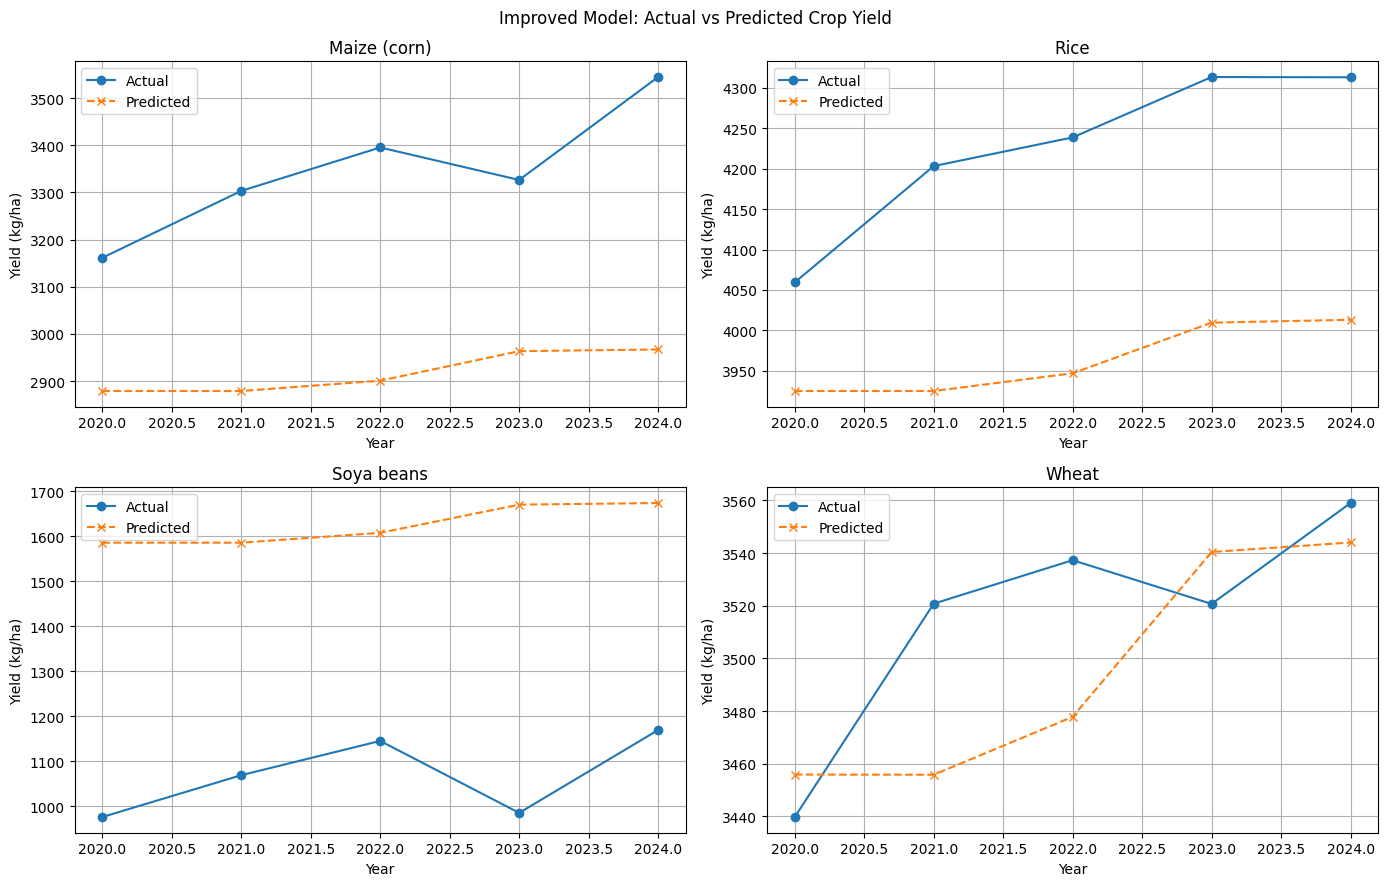

All final project files saved successfully!


In [26]:
import matplotlib.pyplot as plt

# Save improved predictions
results = test_data[["Year", "Crop"]].copy()
results["Actual Yield"] = y_test.values
results["Predicted Yield"] = improved_predictions.round(2)

# Plot crop-wise comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, crop in zip(axes.flatten(), results["Crop"].unique()):
    data = results[results["Crop"] == crop]

    ax.plot(data["Year"], data["Actual Yield"],
            marker="o", label="Actual")

    ax.plot(data["Year"], data["Predicted Yield"],
            marker="x", linestyle="--", label="Predicted")

    ax.set_title(crop)
    ax.set_xlabel("Year")
    ax.set_ylabel("Yield (kg/ha)")
    ax.legend()
    ax.grid(True)

plt.suptitle("Improved Model: Actual vs Predicted Crop Yield")
plt.tight_layout()
plt.savefig("Improved_Model_Graph.png", dpi=300)
plt.show()

# Save project datasets and predictions
final_data.to_csv("Final_Climate_Crop_Dataset.csv", index=False)
results.to_csv("Future_Yield_Predictions.csv", index=False)

print("All final project files saved successfully!")

CLIMATE CHANGE AND CROP YIELD ANALYSIS

1. DATA VERIFICATION
Total records: 100
Missing values: 0
Duplicate rows: 0
Crops: ['Maize (corn)' 'Rice' 'Soya beans' 'Wheat']

2. CORRELATION ANALYSIS


,Crop,Temperature Correlation,Rainfall Correlation
0,Maize (corn),-0.399,0.505
1,Rice,-0.462,0.522
2,Soya beans,-0.038,0.314
3,Wheat,-0.352,0.382


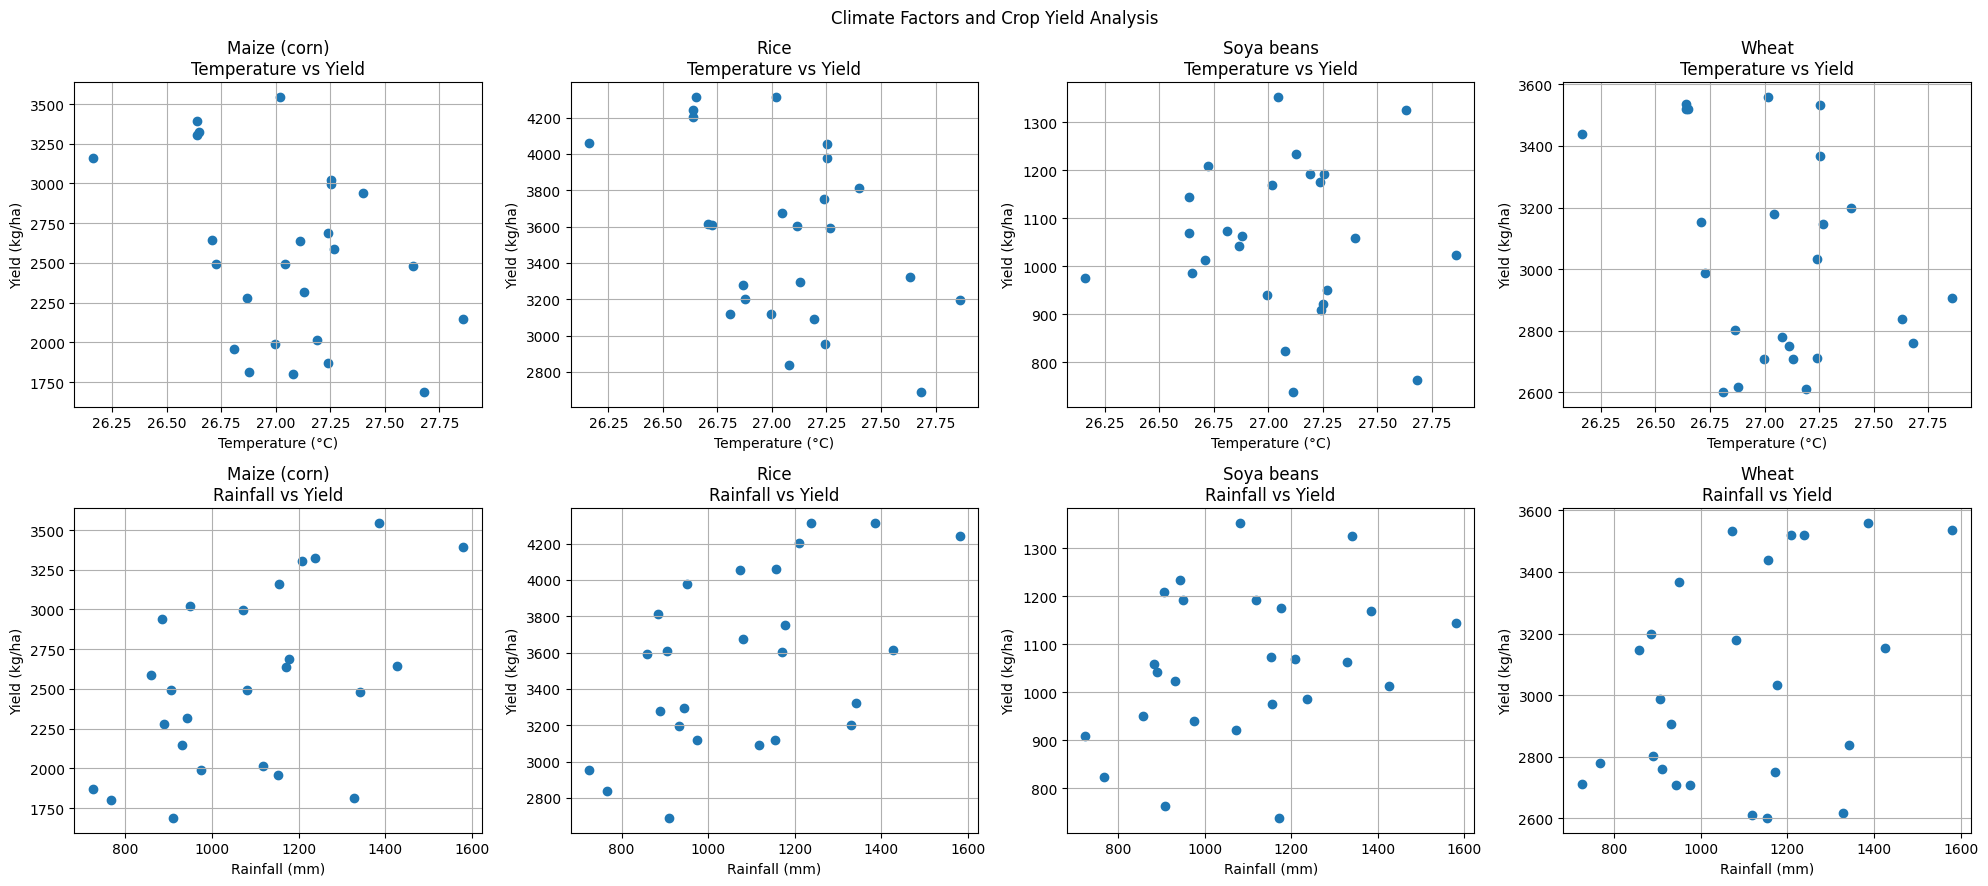


3. MACHINE LEARNING MODEL

4. OVERALL MODEL PERFORMANCE
MAE: 124.56 kg/ha
RMSE: 151.12 kg/ha
R2 Score: 0.984

5. CROP-WISE MODEL PERFORMANCE


,Crop,MAE,RMSE
0,Maize (corn),135.27,161.11
1,Rice,54.06,93.94
2,Soya beans,119.66,132.92
3,Wheat,189.26,197.24


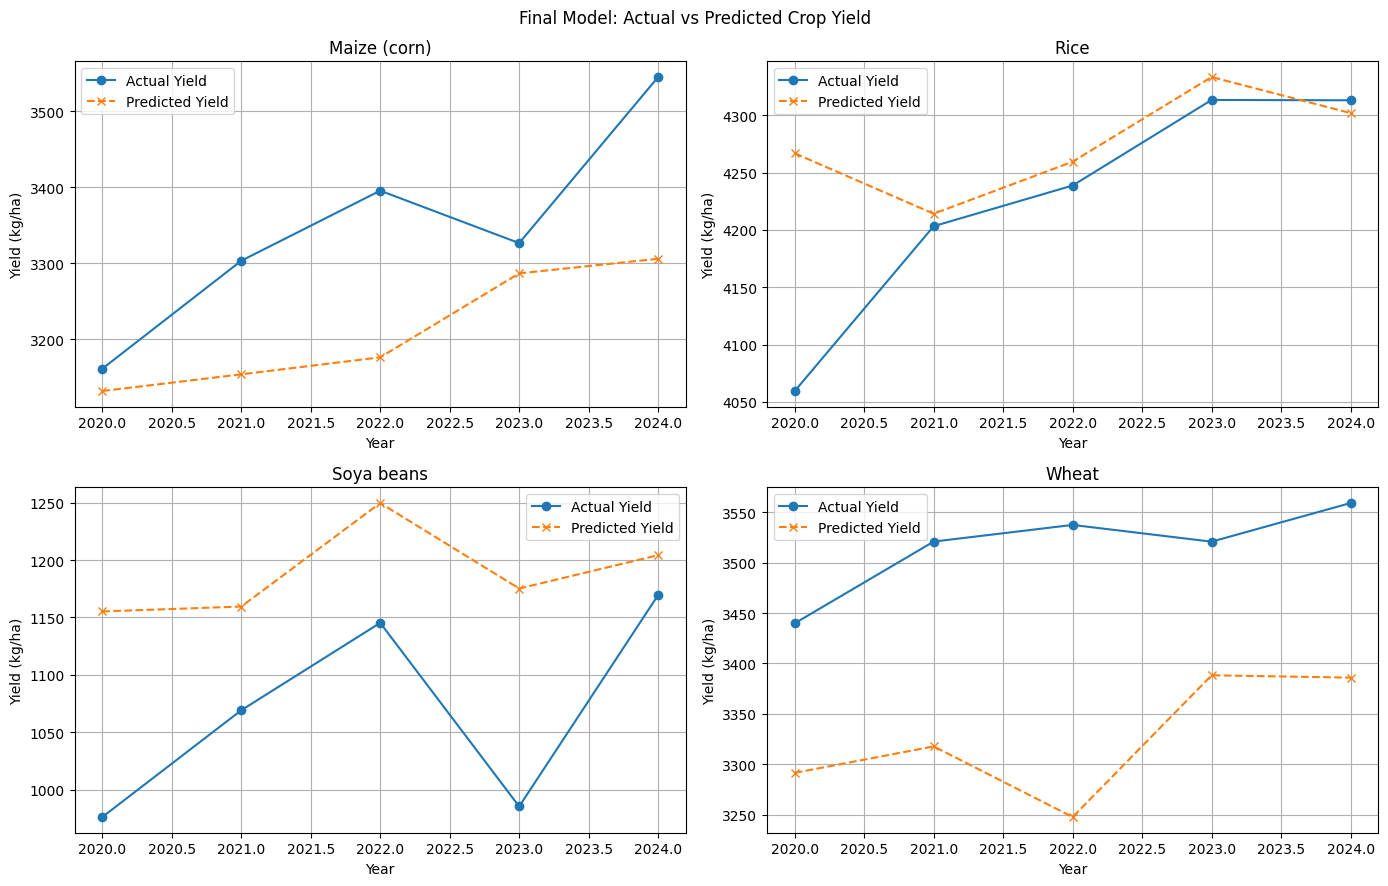


PROJECT ANALYSIS COMPLETED SUCCESSFULLY!

Files created:
1. Final_Climate_Crop_Dataset.csv
2. Final_Crop_Predictions.csv
3. Crop_Correlation_Results.csv
4. Crop_Model_Performance.csv
5. Climate_Correlation_Graphs.png
6. Final_Prediction_Graph.png


In [27]:
# ==========================================================
# CLIMATE CHANGE AND CROP YIELD ANALYSIS - FINAL PROJECT
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 60)
print("CLIMATE CHANGE AND CROP YIELD ANALYSIS")
print("=" * 60)


# 1. MERGE AND VERIFY DATA

final_data = pd.merge(
    crop_clean,
    climate_yearly,
    on="Year",
    how="inner"
)

final_data = final_data.sort_values(
    ["Crop", "Year"]
).reset_index(drop=True)

print("\n1. DATA VERIFICATION")
print("Total records:", len(final_data))
print("Missing values:", final_data.isnull().sum().sum())
print("Duplicate rows:", final_data.duplicated().sum())
print("Crops:", final_data["Crop"].unique())


# 2. CORRELATION ANALYSIS

print("\n2. CORRELATION ANALYSIS")

correlation_results = []

for crop in final_data["Crop"].unique():

    data = final_data[final_data["Crop"] == crop]

    temp_corr = data["Yield"].corr(data["Avg_Temperature"])
    rain_corr = data["Yield"].corr(data["Total_Rainfall"])

    correlation_results.append({
        "Crop": crop,
        "Temperature Correlation": temp_corr,
        "Rainfall Correlation": rain_corr
    })

correlation_table = pd.DataFrame(correlation_results)

display(correlation_table.round(3))


# 3. CLIMATE VS CROP YIELD GRAPHS

fig, axes = plt.subplots(2, 4, figsize=(20, 9))

for i, crop in enumerate(final_data["Crop"].unique()):

    data = final_data[final_data["Crop"] == crop]

    axes[0, i].scatter(
        data["Avg_Temperature"], data["Yield"]
    )
    axes[0, i].set_title(crop + "\nTemperature vs Yield")
    axes[0, i].set_xlabel("Temperature (°C)")
    axes[0, i].set_ylabel("Yield (kg/ha)")
    axes[0, i].grid(True)

    axes[1, i].scatter(
        data["Total_Rainfall"], data["Yield"]
    )
    axes[1, i].set_title(crop + "\nRainfall vs Yield")
    axes[1, i].set_xlabel("Rainfall (mm)")
    axes[1, i].set_ylabel("Yield (kg/ha)")
    axes[1, i].grid(True)

plt.suptitle("Climate Factors and Crop Yield Analysis")
plt.tight_layout()
plt.savefig("Climate_Correlation_Graphs.png", dpi=300)
plt.show()


# 4. TRAIN AND TEST MACHINE LEARNING MODELS
# Train: 2000-2019
# Test: 2020-2024
# Separate model for each crop

print("\n3. MACHINE LEARNING MODEL")

train_data = final_data[final_data["Year"] <= 2019].copy()
test_data = final_data[final_data["Year"] >= 2020].copy()

prediction_results = []
crop_models = {}

features = [
    "Year",
    "Avg_Temperature",
    "Total_Rainfall"
]

for crop in final_data["Crop"].unique():

    train_crop = train_data[train_data["Crop"] == crop]
    test_crop = test_data[test_data["Crop"] == crop]

    X_train = train_crop[features]
    y_train = train_crop["Yield"]

    X_test = test_crop[features]
    y_test = test_crop["Yield"]

    model = LinearRegression()
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    crop_models[crop] = model

    for year, actual, predicted in zip(
        test_crop["Year"],
        y_test,
        predictions
    ):

        prediction_results.append({
            "Crop": crop,
            "Year": year,
            "Actual Yield": actual,
            "Predicted Yield": predicted
        })


# 5. MODEL PERFORMANCE

results = pd.DataFrame(prediction_results)

actual = results["Actual Yield"]
predicted = results["Predicted Yield"]

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
r2 = r2_score(actual, predicted)

print("\n4. OVERALL MODEL PERFORMANCE")
print("MAE:", round(mae, 2), "kg/ha")
print("RMSE:", round(rmse, 2), "kg/ha")
print("R2 Score:", round(r2, 3))

print("\n5. CROP-WISE MODEL PERFORMANCE")

performance = []

for crop in results["Crop"].unique():

    data = results[results["Crop"] == crop]

    performance.append({
        "Crop": crop,
        "MAE": mean_absolute_error(
            data["Actual Yield"],
            data["Predicted Yield"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            data["Actual Yield"],
            data["Predicted Yield"]
        ))
    })

performance_table = pd.DataFrame(performance)

display(performance_table.round(2))


# 6. FINAL ACTUAL VS PREDICTED GRAPHS

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, crop in zip(
    axes.flatten(),
    results["Crop"].unique()
):

    data = results[results["Crop"] == crop]

    ax.plot(
        data["Year"],
        data["Actual Yield"],
        marker="o",
        label="Actual Yield"
    )

    ax.plot(
        data["Year"],
        data["Predicted Yield"],
        marker="x",
        linestyle="--",
        label="Predicted Yield"
    )

    ax.set_title(crop)
    ax.set_xlabel("Year")
    ax.set_ylabel("Yield (kg/ha)")
    ax.legend()
    ax.grid(True)

plt.suptitle("Final Model: Actual vs Predicted Crop Yield")
plt.tight_layout()
plt.savefig("Final_Prediction_Graph.png", dpi=300)
plt.show()


# 7. SAVE ALL PROJECT FILES

final_data.to_csv(
    "Final_Climate_Crop_Dataset.csv",
    index=False
)

results.to_csv(
    "Final_Crop_Predictions.csv",
    index=False
)

correlation_table.to_csv(
    "Crop_Correlation_Results.csv",
    index=False
)

performance_table.to_csv(
    "Crop_Model_Performance.csv",
    index=False
)

print("\n" + "=" * 60)
print("PROJECT ANALYSIS COMPLETED SUCCESSFULLY!")
print("=" * 60)

print("\nFiles created:")
print("1. Final_Climate_Crop_Dataset.csv")
print("2. Final_Crop_Predictions.csv")
print("3. Crop_Correlation_Results.csv")
print("4. Crop_Model_Performance.csv")
print("5. Climate_Correlation_Graphs.png")
print("6. Final_Prediction_Graph.png")

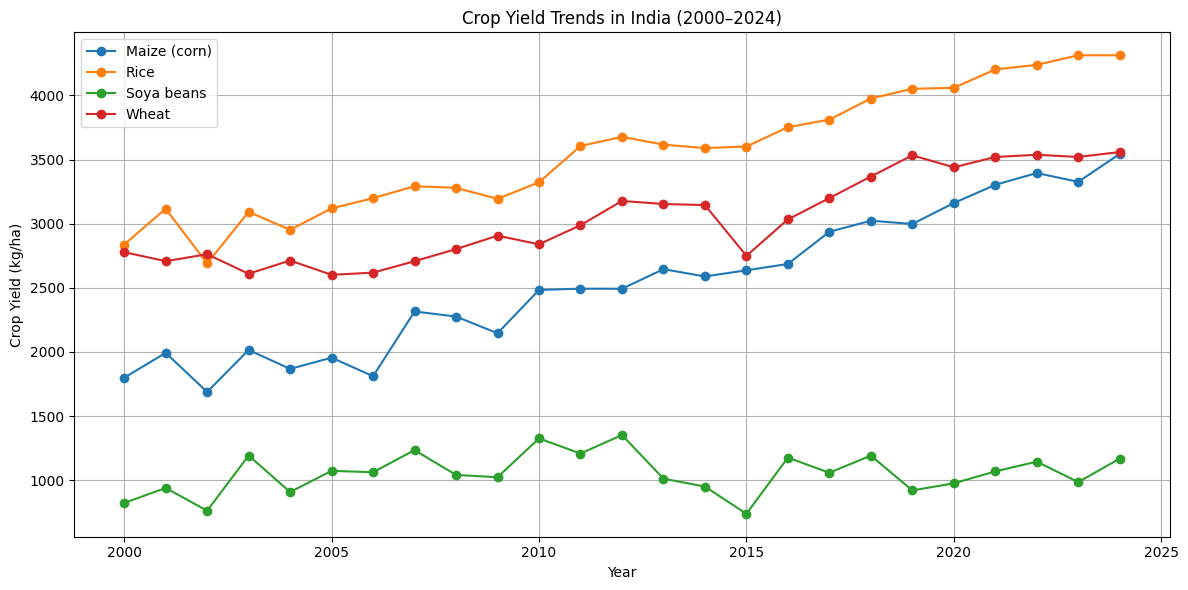

Added: Final_Climate_Crop_Dataset.csv
Added: Final_Crop_Predictions.csv
Added: Crop_Correlation_Results.csv
Added: Crop_Model_Performance.csv
Added: Crop_Yield_Trends_2000_2024.png
Added: Climate_Correlation_Graphs.png
Added: Final_Prediction_Graph.png

Project ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import matplotlib.pyplot as plt
import zipfile
import os

# Safety check to ensure variables exist before plotting and packaging
try:
    # Save crop yield trend graph
    plt.figure(figsize=(12, 6))

    for crop in final_data["Crop"].unique():
        data = final_data[final_data["Crop"] == crop]
        plt.plot(
            data["Year"], data["Yield"],
            marker="o", label=crop
        )

    plt.title("Crop Yield Trends in India (2000–2024)")
    plt.xlabel("Year")
    plt.ylabel("Crop Yield (kg/ha)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("Crop_Yield_Trends_2000_2024.png", dpi=300)
    plt.show()

    # Save all final datasets
    final_data.to_csv("Final_Climate_Crop_Dataset.csv", index=False)
    results.to_csv("Final_Crop_Predictions.csv", index=False)
    correlation_table.to_csv("Crop_Correlation_Results.csv", index=False)
    performance_table.to_csv("Crop_Model_Performance.csv", index=False)

    # Collect project files
    project_files = [
        "Final_Climate_Crop_Dataset.csv",
        "Final_Crop_Predictions.csv",
        "Crop_Correlation_Results.csv",
        "Crop_Model_Performance.csv",
        "Crop_Yield_Trends_2000_2024.png",
        "Climate_Correlation_Graphs.png",
        "Final_Prediction_Graph.png"
    ]

    # Create ZIP file
    zip_name = "Climate_Crop_Yield_Project_Files.zip"

    with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
        for file in project_files:
            if os.path.exists(file):
                z.write(file)
                print("Added:", file)
            else:
                print("Not found:", file)

    print("\nProject ZIP created successfully!")

    from google.colab import files
    files.download(zip_name)

except NameError as e:
    print(f"Error: {e}")
    print("Please run the main analytical code cell (q9tGPbt6vWPz) above first to populate the variables before executing this download block!")